## Implementation of Linear regression using python

In [1]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [2]:
DF1=pd.read_csv("weight-height - weight-height.csv")


### Standardize numerical features

In [3]:
col=["Height","Weight"]
s1=MinMaxScaler()
DF1[col]=s1.fit_transform(DF1[col])
DF1.head()


,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [4]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

## Split the data into training and test set

In [5]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [6]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [7]:
## Training  Linear regressions model 

In [8]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [9]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


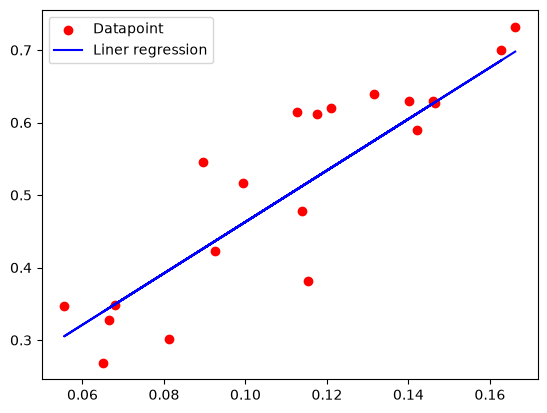

In [10]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [11]:
## Load the Height and weight  to indipendent and dependent variable 

In [12]:
df2=pd.read_csv("weight-height - weight-height.csv")
X=df2["Height"].values.reshape(-1,1)
X.shape
Y=df2["Weight"].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [13]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [14]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [15]:

# Weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations = 1000
learningrate = 0.01

# Gradient Descent
mseh = []
m = X.shape[0]

for i in range(iterations):
    # Calculate predictions
    Y_pred = X @ theta

    # Calculate Mean Squared Error
    error = Y_pred - Y
    mse = np.mean(error ** 2)
    mseh.append(mse)

    # Calculate gradient and update parameters
    gradient = (2 / m) * (X.T @ error)
    theta = theta - learningrate * gradient

print("Final MSE:", mseh[-1])
print("Final parameters:", theta)
print("Number of iterations:", len(mseh))


Final MSE: 0.2869054913354277
Final parameters: [1.32222677e-15 8.44449232e-01]
Number of iterations: 1000


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

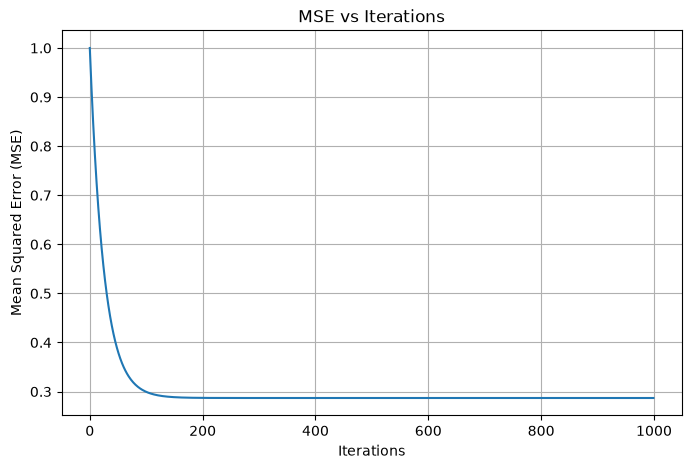

In [16]:
# Plot the MSE over iteration

# Ensure mseh contains MSE values from the training loop
if len(mseh) == 0:
    print("Error: mseh is empty. Run the gradient descent training cell first.")
else:
    plt.figure(figsize=(8, 5))
    plt.plot(range(len(mseh)), mseh)
    plt.xlabel('Iterations')
    plt.ylabel('Mean Squared Error (MSE)')
    plt.title('MSE vs Iterations')
    plt.grid(True)
    plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("Food_Delivery_Times - Food_Delivery_Times.csv")

print(df.head())
print(df.info())

   Order_ID  Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  \
0       522         7.93   Windy           Low   Afternoon      Scooter   
1       738        16.42   Clear        Medium     Evening         Bike   
2       741         9.52   Foggy           Low       Night      Scooter   
3       661         7.44   Rainy        Medium   Afternoon      Scooter   
4       412        19.03   Clear           Low     Morning         Bike   

   Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min  
0                    12                     1.0                 43  
1                    20                     2.0                 84  
2                    28                     1.0                 59  
3                     5                     1.0                 37  
4                    16                     5.0                 68  
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Cou

In [18]:
features = [
    "Distance_km",
    "Preparation_Time_min",
    "Traffic_Level",
    "Weather"
]

df = df.dropna(subset=features + ["Delivery_Time_min"])

X = pd.get_dummies(df[features], columns=["Traffic_Level", "Weather"],
                   drop_first=True, dtype=int)

Y = df["Delivery_Time_min"]

print(X.head())
print(Y.head())

   Distance_km  Preparation_Time_min  Traffic_Level_Low  Traffic_Level_Medium  \
0         7.93                    12                  1                     0   
1        16.42                    20                  0                     1   
2         9.52                    28                  1                     0   
3         7.44                     5                  0                     1   
4        19.03                    16                  1                     0   

   Weather_Foggy  Weather_Rainy  Weather_Snowy  Weather_Windy  
0              0              0              0              1  
1              0              0              0              0  
2              1              0              0              0  
3              0              1              0              0  
4              0              0              0              0  
0    43
1    84
2    59
3    37
4    68
Name: Delivery_Time_min, dtype: int64


In [19]:
scaler = StandardScaler()

X[["Distance_km", "Preparation_Time_min"]] = scaler.fit_transform(
    X[["Distance_km", "Preparation_Time_min"]]
)

In [20]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=67
)

In [21]:
model = LinearRegression()

model.fit(X_train, Y_train)

Y_pred = model.predict(X_test)

In [22]:
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("Mean Absolute Error:", mae)
print("R-squared:", r2)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Mean Squared Error: 103.18196840004212
Root Mean Squared Error: 10.157852548646398
Mean Absolute Error: 6.4887159100030685
R-squared: 0.768559544894301
Coefficients: [ 17.19871974   7.41727125 -11.43447035  -5.93535823   9.45539421
   5.80761168  10.35390968   2.75778956]
Intercept: 60.18594151677324


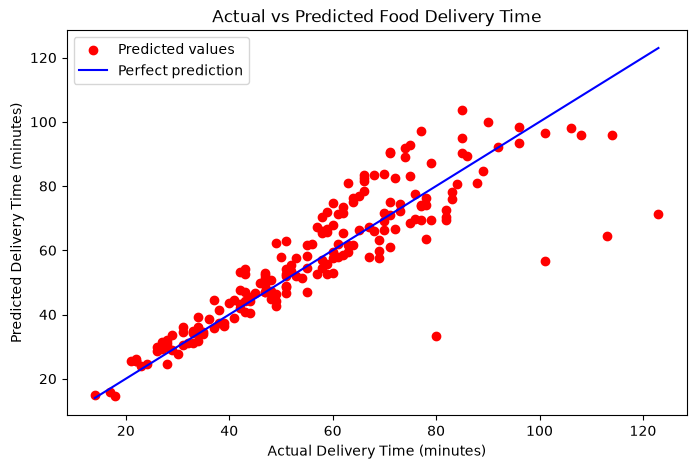

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(Y_test, Y_pred, color="red", label="Predicted values")
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color="blue",
    label="Perfect prediction"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Food Delivery Time")
plt.legend()
plt.show()